# Лекция 6. Ценность без таблицы: аппроксимация функций и первый шаг в Deep RL

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/06-approximation/lecture/lecture.ipynb)

**Главный вопрос сегодня: как учить ценность, когда состояний слишком много для таблицы, — и почему такое обучение может разойтись?**

Карта пути. Q-learning и SARSA (лекции 3 и 4) хранили по числу на каждую пару «состояние, действие». Сегодня состояние — два непрерывных числа, и у таблицы есть беда: каждая её клетка учится отдельно. Заменим таблицу функцией с весами — сначала линейной, потом нейросетью, так же как в лекции 5 нейросеть заменила таблицу вероятностей. Увидим, что одно обновление теперь меняет оценку сразу во многих состояниях: это ускоряет обучение — и может его сломать. В конце разберём пример, где обучение разлетается, хотя все награды равны нулю, и что из этого следует для DQN на следующей неделе.

Лекция устроена как прошлые: раздел начинается с вопроса, на который мы **голосуем всей аудиторией**, и только потом проверяем ответ запуском. Вопросы и песочница — на странице-спутнике, откройте её на телефоне:

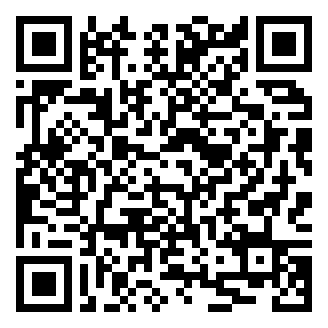

[ilyachichkanov.github.io/Reinforcement-learning/lecture06.html](https://ilyachichkanov.github.io/Reinforcement-learning/lecture06.html)

| | Раздел | Минут |
|---|---|---|
| 1 | 🔁 Где кончается таблица | 8 |
| 2 | Таблица — это линейная функция | 14 |
| 3 | Semi-gradient: учимся по своей же оценке | 20 |
| 4 | Нейросеть вместо плиток: одно обновление меняет всё | 12 |
| 5 | Смертельная триада | 22 |
| 6 | ⏱ Что приближаем: стратегию, ценность или обе | 6 |
| 7 | Итоги и где это работает | 8 |

Пометки: **🔁** — вспоминаем пройденное, **⏱** — резерв, если останется время. Служебный код лежит в `fa_plots.py`: среда, признаки и рисовальщики; читать его не нужно.

In [1]:
# Служебный модуль лекции. Локально он уже в репозитории, в Google Colab — скачивается.
import pathlib, urllib.request
REPO = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main/"
if not pathlib.Path("fa_plots.py").exists():
    urllib.request.urlretrieve(REPO + "06-approximation/lecture/fa_plots.py", "fa_plots.py")
import importlib.util, subprocess, sys     # горной машине нужен gymnasium, сети в разделе 4 — torch
for package in ("gymnasium", "torch"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from fa_plots import *     # make_mountain_car, GridFeatures, TileFeatures, рисовальщики

## 1. 🔁 Где кончается таблица

Задача раздела: вспомнить, как таблица хранит ценности, и увидеть, чего она не умеет, когда состояние — непрерывные числа.

**Среда — горная машина (`MountainCar-v0`).** Машина стоит в низшей точке между двумя горками и должна заехать на правую, к флагу. Мотор слабый: в лоб не въехать, нужно раскачаться.

* *Состояние* — два числа: позиция $x \in [-1.2,\ 0.6]$ и скорость $v \in [-0.07,\ 0.07]$.
* *Действия* — три: толкать ←, не толкать, толкать →.
* *Награда* — $-1$ за каждый шаг: чем быстрее машина доедет, тем больше сумма наград.
* *Конец эпизода* — у флага ($x \ge 0.5$) или через 200 шагов.

наблюдение: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
действий: 3


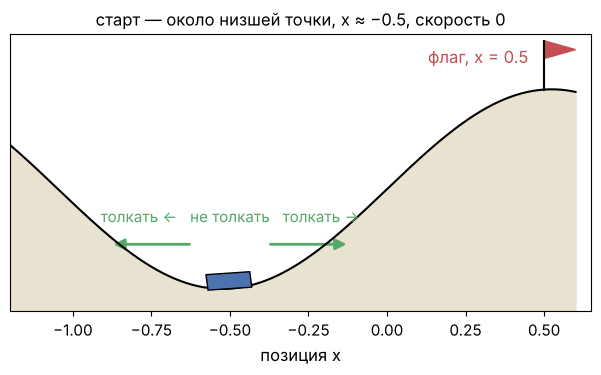

In [3]:
car = make_mountain_car()
print("наблюдение:", car.observation_space)
print("действий:", car.action_space.n)
draw_mountain_car(x=-0.5, title="старт — около низшей точки, x ≈ −0.5, скорость 0")
plt.show()

Позиций и скоростей бесконечно много, а таблице нужен номер строки. Старый приём — разрезать поле $(x, v)$ на сетку $20 \times 20$: состояние — номер клетки, в таблице $400 \times 3$ чисел.

В коде сетка — функция `grid(s)`: она возвращает номер клетки, в которую попала точка $s$, списком из одного числа (зачем список — станет ясно в разделе 2). Таблица — массив `W` размера $400 \times 3$, его строка `W[клетка]` — оценки трёх действий. Шляпка в $\hat q(s, a)$ напоминает, что это оценка, а не настоящая ценность.

Обучаем SARSA из лекции 4: после каждого шага клетка $s$ сдвигается к цели $r + \gamma\, \hat q(s', a')$, где $a'$ — следующее действие по ε-жадной стратегии:

$$\hat q(s, a) \leftarrow \hat q(s, a) + \alpha\,\big(r + \gamma\, \hat q(s', a') - \hat q(s, a)\big).$$

У флага дальше наград нет, и цель — просто $r$. Настройки: шаг $\alpha = 0.5$, $\gamma = 1$, случайное действие с вероятностью $\varepsilon = 0.1$, 300 эпизодов. Массив `visits` считает, сколько раз обновлялась каждая клетка.

In [4]:
def epsilon_greedy(q, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(len(q)))
    return int(rng.choice(np.flatnonzero(q == q.max())))     # среди равных — случайно


def train_sarsa(features, alpha, episodes=300, seed=0, eps=0.1, gamma=1.0):
    # SARSA на горной машине. Оценка q̂(s, a) = W[features(s), a].sum(); для сетки это строка таблицы.
    env, rng = make_mountain_car(), np.random.default_rng(seed)
    W = np.zeros((features.n, 3))
    visits = np.zeros(features.n, dtype=int)
    lengths = []
    for episode in range(episodes):
        s, _ = env.reset(seed=seed * 10_000 + episode)
        x = features(s)                                      # номера признаков точки s
        a = epsilon_greedy(W[x].sum(axis=0), eps, rng)
        for t in range(1, 201):
            s2, r, terminated, truncated, _ = env.step(a)
            if terminated:                                   # у флага: цель — просто r
                target = r
            else:
                x2 = features(s2)
                a2 = epsilon_greedy(W[x2].sum(axis=0), eps, rng)
                target = r + gamma * W[x2, a2].sum()         # r + γ q̂(s′, a′)
            W[x, a] += alpha * (target - W[x, a].sum())      # q̂(s, a) += α (цель − q̂(s, a))
            visits[x] += 1
            if terminated or truncated:
                break
            x, a = x2, a2
        lengths.append(t)
    return W, np.array(lengths), visits


grid = GridFeatures(bins=20)
print("номер клетки старта:", grid(np.array([-0.5, 0.0])), "  клеток всего:", grid.n)

номер клетки старта: [150]   клеток всего: 400


**Вопрос 1 (голосуем).** Таблица на сетке $20 \times 20$ обучалась 300 эпизодов. Машина попала в клетку, которую за всё обучение не обновили ни разу, а соседнюю клетку обновили несколько десятков раз. Какие оценки $\hat q$ даст таблица в этой клетке?

* **A.** средние оценки соседних клеток;
* **B.** нули — те же числа, что до обучения;
* **C.** оценки ближайшей обновлённой клетки;
* **D.** случайные числа.

Проверим: обучим таблицу и найдём такую клетку.

клеток, которые не обновлялись ни разу: 156 из 400
нетронутая клетка x ≈ +0.37, v ≈ +0.0035: обновлений   0,  оценки трёх действий [0. 0. 0.]
соседняя   клетка x ≈ +0.28, v ≈ +0.0035: обновлений  43,  оценки трёх действий [-4.7 -5.5 -5.6]


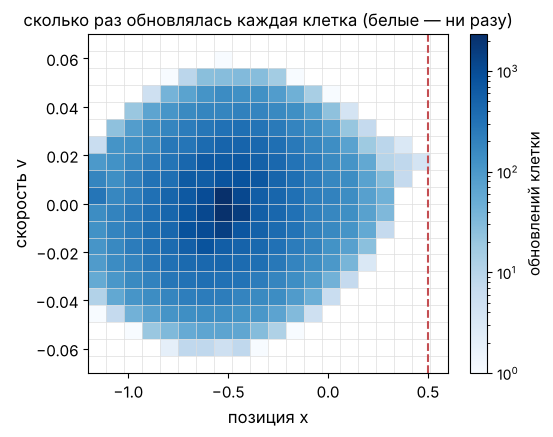

In [5]:
W_grid, lengths_grid, visits = train_sarsa(grid, alpha=0.5, seed=0)
visits = visits.reshape(grid.bins, grid.bins)            # [номер отрезка позиции, номер отрезка скорости]
untouched = visits == 0
print(f"клеток, которые не обновлялись ни разу: {untouched.sum()} из {grid.n}")

# нетронутая клетка, соседку которой обновляли чаще всего
pairs = [((i, j), (i + di, j + dj)) for i, j in zip(*np.nonzero(untouched))
         for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1))
         if 0 <= i + di < grid.bins and 0 <= j + dj < grid.bins]
empty, neighbour = max(pairs, key=lambda pair: visits[pair[1]])
for name, (i, j) in (("нетронутая", empty), ("соседняя", neighbour)):
    x, v = LOW + (np.array([i, j]) + 0.5) * (HIGH - LOW) / grid.bins     # середина клетки
    print(f"{name:10s} клетка x ≈ {x:+.2f}, v ≈ {v:+.4f}: обновлений {visits[i, j]:3d},"
          f"  оценки трёх действий {W_grid[i * grid.bins + j].round(1)}")

plot_visits(visits, title="сколько раз обновлялась каждая клетка (белые — ни разу)")
plt.show()

Ответ **B** — нули, как до обучения. Таблица сдвигает только ту клетку, где побывала машина, — нетронутая клетка осталась прежней, хотя у соседней клетки, которую обновили 43 раза, оценки уже от −5.6 до −4.7. Белых клеток на карте 156 из 400: в них машина за 300 эпизодов не попала ни разу.

Почему так выходит: у каждой клетки — свои три числа, и обновление одной клетки не трогает другие. Соседние точки поля, где ценности почти одинаковы, учатся порознь, и каждую машине нужно посетить самой. На двух числах это ещё терпимо. Если состояние — кадр игры $84 \times 84$ пикселя, один и тот же кадр почти никогда не повторяется, и таблица не выучит ничего.

**Одной строкой:** таблица учит каждую клетку отдельно — там, где агент не был, она не знает ничего.

## 2. Таблица — это линейная функция

Задача раздела: записать таблицу как функцию с весами — так, чтобы её можно было заменить другой функцией, где одно обновление учит и соседние точки.

Опишем точку $s$ числами-**признаками** $x_1(s), \dots, x_n(s)$, каждое равно 0 или 1, и будем считать оценку суммой весов:

$$\hat q(s, a) = \sum_{i=1}^{n} x_i(s)\, W[i, a].$$

Для сетки признак $x_i(s) = 1$, если точка $s$ лежит в клетке $i$, и $0$ иначе. Единица ровно одна, и сумма из одного слагаемого — строка таблицы `W[клетка, a]`. Поэтому `grid(s)` и возвращает список — номера признаков, равных 1. Проверим на точке ★ $(x = -0.5,\ v = 0)$ и таблице из раздела 1.

In [6]:
star = np.array([-0.5, 0.0])                         # точка ★: низшая точка, скорость 0
x_star = np.zeros(grid.n)
x_star[grid(star)] = 1                                # признаки ★: 400 чисел, одна единица
print("единиц в x(★):", int(x_star.sum()))
print("сумма x_i(★)·W[i, a] по 400 клеткам:", (x_star @ W_grid).round(2))
print("строка таблицы W[клетка ★]:          ", W_grid[grid(star)][0].round(2))

единиц в x(★): 1
сумма x_i(★)·W[i, a] по 400 клеткам: [-88.52 -83.43 -77.1 ]
строка таблицы W[клетка ★]:           [-88.52 -83.43 -77.1 ]


Как сдвигать веса, если для точки $s$ известна цель $y$ — число, к которому должна прийти оценка? Уменьшаем квадрат ошибки $L = \tfrac12\big(y - \hat q(s, a)\big)^2$ шагом градиентного спуска. Производная по весу $W[i, a]$ — по правилу для сложной функции:

$$\frac{\partial L}{\partial W[i, a]} = -\big(y - \hat q(s, a)\big) \cdot \frac{\partial \hat q(s, a)}{\partial W[i, a]} = -\big(y - \hat q(s, a)\big)\, x_i(s),$$

потому что в сумме $\sum_i x_i(s) W[i, a]$ от $W[i, a]$ зависит одно слагаемое. Шаг против градиента:

$$W[i, a] \leftarrow W[i, a] + \alpha\,\big(y - \hat q(s, a)\big)\, x_i(s).$$

Сдвигаются только веса признаков, равных 1. Сделаем такой шаг в точке ★ для действия «толкать →» к цели $y = -10$, $\alpha = 0.5$:

In [7]:
y, a, alpha = -10.0, 2, 0.5                           # цель, действие «толкать →», шаг
W = W_grid.copy()
W[:, a] += alpha * (y - x_star @ W[:, a]) * x_star    # шаг градиента сразу для всех 400 весов
print("сколько весов изменилось:", int((W != W_grid).sum()))
print(f"q̂(★, →): {x_star @ W_grid[:, a]:.2f} -> {x_star @ W[:, a]:.2f}")

сколько весов изменилось: 1
q̂(★, →): -77.10 -> -43.55


Изменился один вес — клетка ★, и её оценка прошла половину пути к цели. Ровно так обновляет таблица в разделе 1: **обновление таблицы — это шаг градиентного спуска** для линейной функции с признаками-клетками.

Теперь возьмём другие признаки — **плитки** (tile coding). Положим на поле 8 сеток $8 \times 8$, каждую чуть сдвинем относительно предыдущей. Точка лежит в одной плитке каждой сетки, поэтому у неё 8 признаков, равных 1, а оценка — сумма 8 весов. Ниже — первые три сетки и плитки, в которые попала точка ★.

признаков всего: 648   номера признаков точки ★, равных 1: [ 31 112 193 275 356 437 519 600]


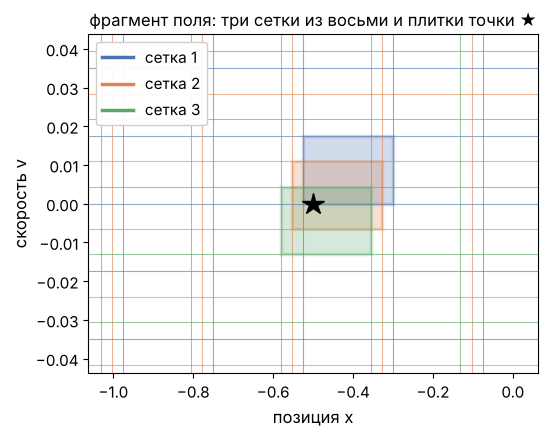

In [8]:
tiles = TileFeatures(n=8, tilings=8)
print("признаков всего:", tiles.n, "  номера признаков точки ★, равных 1:", tiles(star))
draw_tilings(tiles, star, title="фрагмент поля: три сетки из восьми и плитки точки ★")
plt.show()

**Вопрос 2 (голосуем).** Признаки — 8 сеток плиток. Сделали одно обновление в точке ★: сдвинули её 8 весов. Где изменится оценка $\hat q$?

* **A.** только в самой точке ★;
* **B.** во всей клетке сетки $20 \times 20$, где лежит ★, одинаково;
* **C.** в пятне вокруг ★: чем ближе к ★, тем сильнее;
* **D.** на всём поле.

Проверим: посчитаем, во сколько раз сдвинулась оценка в каждой точке поля по сравнению со сдвигом в самой ★. Рядом — то же для сетки $20 \times 20$.

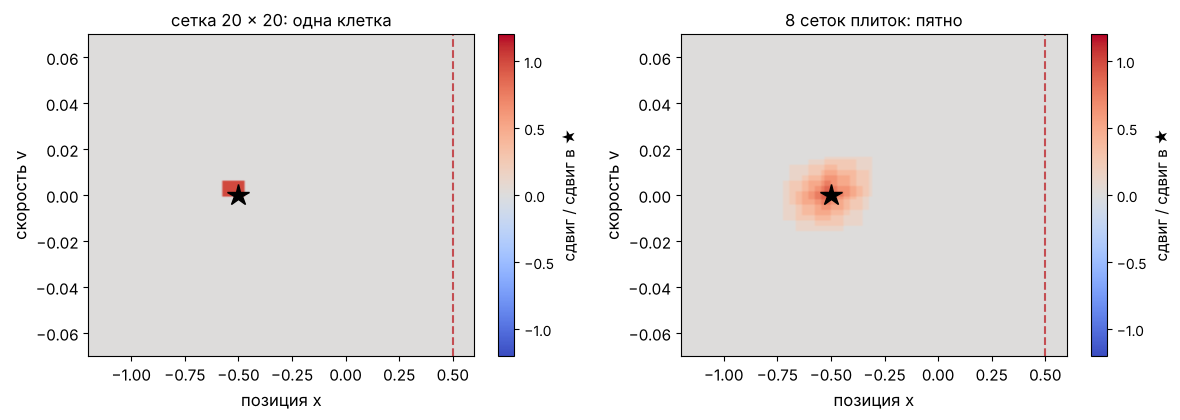

In [9]:
points, shape = plane()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
plot_footprint(footprint_linear(grid, star, points), shape, star, ax=axes[0], title="сетка 20 × 20: одна клетка")
plot_footprint(footprint_linear(tiles, star, points), shape, star, ax=axes[1], title="8 сеток плиток: пятно")
plt.tight_layout(); plt.show()

Ответ **C** — в пятне вокруг ★. Оценка в точке $s'$ меняется на сумму сдвигов её весов, а сдвинулись только веса признаков точки ★:

$$\Delta \hat q(s') = \alpha\,\big(y - \hat q(★)\big) \sum_i x_i(s')\, x_i(★).$$

Сумма $\sum_i x_i(s') x_i(★)$ — это число плиток, общих у $s'$ и ★. В самой ★ их 8, у соседних точек от 1 до 7, у далёких — 0. У сетки общая клетка или есть, или нет: сдвигается вся клетка ★ целиком, и больше ничего.

**Одной строкой:** таблица — линейная функция с признаками-клетками; с плитками одно обновление учит пятно соседних точек.

## 3. Semi-gradient: учимся по своей же оценке

Задача раздела: в разделе 2 цель $y$ была дана. В RL её никто не даёт — что подставить и как тогда считать градиент? И окупается ли пятно плиток на настоящем обучении?

SARSA подставляет вместо $y$ свою же оценку $r + \gamma\, \hat q(s', a')$. Квадрат ошибки $L = \tfrac12\,\delta^2$, где

$$\delta = r + \gamma\, \hat q(s', a') - \hat q(s, a),$$

зависит от весов дважды: через $\hat q(s, a)$ и через цель. Полный градиент:

$$\frac{\partial L}{\partial W[i, a]} = -\delta\,\big(x_i(s) - \gamma\, x_i(s')\big).$$

Что делает второе слагаемое, посмотрим на двух клетках таблицы: $\hat q(s, a) = -10$, $\hat q(s', a') = -4$, переход с $r = -1$, $\gamma = 1$, $\alpha = 0.5$.

In [10]:
q_s, q_next, r, gamma, alpha = -10.0, -4.0, -1.0, 1.0, 0.5
delta = r + gamma * q_next - q_s
print(f"δ = {delta:+.1f}")
print(f"полный градиент: q̂(s, a) {q_s} -> {q_s + alpha * delta:.1f},   q̂(s′, a′) {q_next} -> {q_next - alpha * gamma * delta:.1f}")
print(f"semi-gradient:   q̂(s, a) {q_s} -> {q_s + alpha * delta:.1f},   q̂(s′, a′) остаётся {q_next}")

δ = +5.0
полный градиент: q̂(s, a) -10.0 -> -7.5,   q̂(s′, a′) -4.0 -> -6.5
semi-gradient:   q̂(s, a) -10.0 -> -7.5,   q̂(s′, a′) остаётся -4.0


Полный градиент опустил оценку следующего состояния с $-4$ до $-6.5$, хотя про $s'$ ничего нового не узнали: цель сама поехала навстречу оценке, будущее подогнали под прошлое. SARSA второе слагаемое отбрасывает: цель считается **числом**, и сдвигается только $\hat q(s, a)$. Такой шаг называют **semi-gradient** (полуградиентным):

$$W[i, a] \leftarrow W[i, a] + \alpha\, \delta\, x_i(s).$$

Код раздела 1 уже такой: `target` вычислен до шага и дальше — просто число.

```python
target = r + gamma * W[x2, a2].sum()           # цель r + γ q̂(s′, a′) — число
W[x, a] += alpha * (target - W[x, a].sum())    # W[i, a] += α δ x_i(s)
```

В PyTorch цель превращают в число методом `.detach()` из мини-семинара по PyTorch: `target = (r + gamma * q_next).detach()`.

Сравним сетку и плитки на обучении. Цикл — `train_sarsa` из раздела 1, настройки те же, различие одно — признаки. У плиток обновление сдвигает 8 весов, поэтому шаг на вес берём в 8 раз меньше, $\alpha = 0.5 / 8$: тогда оценка в самой точке сдвигается к цели на ту же долю, что у таблицы. Проверим одним шагом к цели $-10$:

In [11]:
for name, features, alpha in (("сетка 20 × 20", grid, 0.5), ("8 сеток плиток", tiles, 0.5 / 8)):
    W, x = np.zeros((features.n, 3)), features(star)
    W[x, 2] += alpha * (-10.0 - W[x, 2].sum())         # один шаг в точке ★ к цели −10
    print(f"{name:15s} весов на действие: {features.n},   q̂(★, →) после шага: {W[x, 2].sum():.1f}")

сетка 20 × 20   весов на действие: 400,   q̂(★, →) после шага: -5.0
8 сеток плиток  весов на действие: 648,   q̂(★, →) после шага: -5.0


**Вопрос 3 (голосуем).** По 5 запусков, в каждом 300 эпизодов. У сетки $20 \times 20$ — 400 весов на действие, у плиток — 648. Кто к концу обучения чаще доезжает до флага?

* **A.** сетка: весов меньше, каждый учится быстрее;
* **B.** плитки;
* **C.** поровну: цикл и шаг одни и те же;
* **D.** за 300 эпизодов не доедет ни та, ни другая.

Проверим: обучим и нарисуем, сколько шагов занимал каждый эпизод (200 — машина не доехала).

сетка 20 × 20   доехала в последних 50 эпизодах: [0.   0.06 0.02 0.02 0.06],  шагов в среднем: [200 199 199 199 198]
8 сеток плиток  доехала в последних 50 эпизодах: [0.9  0.88 0.96 0.9  0.96],  шагов в среднем: [159 159 155 161 150]


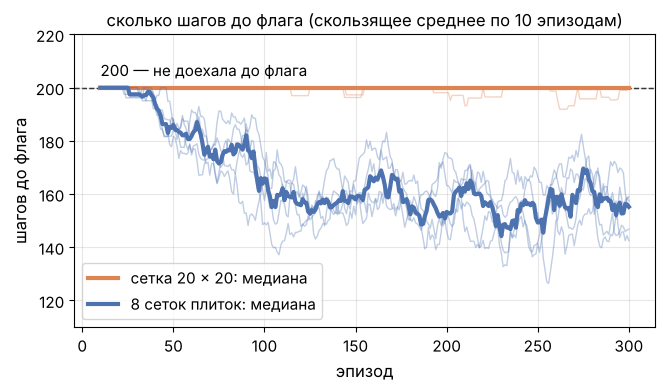

In [12]:
SEEDS = range(5)
runs = {"сетка 20 × 20": [train_sarsa(grid, alpha=0.5, seed=k)[1] for k in SEEDS],
        "8 сеток плиток": [train_sarsa(tiles, alpha=0.5 / 8, seed=k)[1] for k in SEEDS]}
for name, lengths in runs.items():
    lengths = np.array(lengths)
    reached = (lengths[:, -50:] < 200).mean(axis=1)          # эпизод короче 200 шагов — доехала до флага
    print(f"{name:15s} доехала в последних 50 эпизодах: {np.round(reached, 2)},"
          f"  шагов в среднем: {lengths[:, -50:].mean(axis=1).astype(int)}")
plot_lengths(runs, title="сколько шагов до флага (скользящее среднее по 10 эпизодам)")
plt.show()

Ответ **B** — плитки. В последних 50 эпизодах машина с плитками доезжает до флага в 88–96 % эпизодов, с сеткой — в 0–6 %.

Почему так выходит: число весов тут ни при чём — решает, сколько точек учит одно обновление. Одна плитка сетки $8 \times 8$ по площади равна $(20/8)^2 \approx 6$ клеткам сетки $20 \times 20$, а 8 сдвинутых плиток дают пятно ещё шире (картинка раздела 2). Машине не нужно побывать в каждой клетке: соседние точки поля учатся вместе. Это свойство называют **обобщением** (generalization).

**Одной строкой:** semi-gradient — цель считается числом, двигаем только оценку текущего состояния; с плитками этот шаг учит пятно соседей, и машина доезжает до флага.

## 4. Нейросеть вместо плиток: одно обновление меняет всё

Задача раздела: плитки придумал человек, и на кадре игры их не нарежешь. Пусть признаки подбирает нейросеть — так же, как в лекции 5 она считала вероятности действий. Что тогда делает одно обновление?

Оценка ценности $\hat v(s)$ — выход сети $2 \to 64 \to 64 \to 1$, веса — все её параметры. На вход подаём позицию и скорость, переведённые в отрезок $[-1, 1]$ (`normalize`): диапазон скорости в 13 раз уже диапазона позиции, и без перевода сеть почти не различала бы скорость.

Сделаем один шаг градиентного спуска с шагом $\alpha = 0.01$ в точке ★ к цели $y = -10$ — тот же $\tfrac12(y - \hat v(★))^2$, что в разделе 2, только веса теперь — параметры сети.

In [13]:
def make_net(seed=0):
    torch.manual_seed(seed)
    return torch.nn.Sequential(torch.nn.Linear(2, 64), torch.nn.ReLU(),
                               torch.nn.Linear(64, 64), torch.nn.ReLU(),
                               torch.nn.Linear(64, 1))

net = make_net()
print("параметров сети:", sum(p.numel() for p in net.parameters()))

параметров сети: 4417


**Вопрос 4 (голосуем).** Один шаг градиента сети в точке ★. Где изменится оценка $\hat v$?

* **A.** только в самой точке ★;
* **B.** в пятне вокруг ★, как у плиток;
* **C.** по всему полю, и вдали от ★ почти так же сильно, как в ★;
* **D.** нигде заметно: шаг слишком маленький.

Проверим: третья карта к картинке раздела 2.

сдвиг оценки в ★: -0.339,  в дальнем углу (0.6, 0.07): -0.309


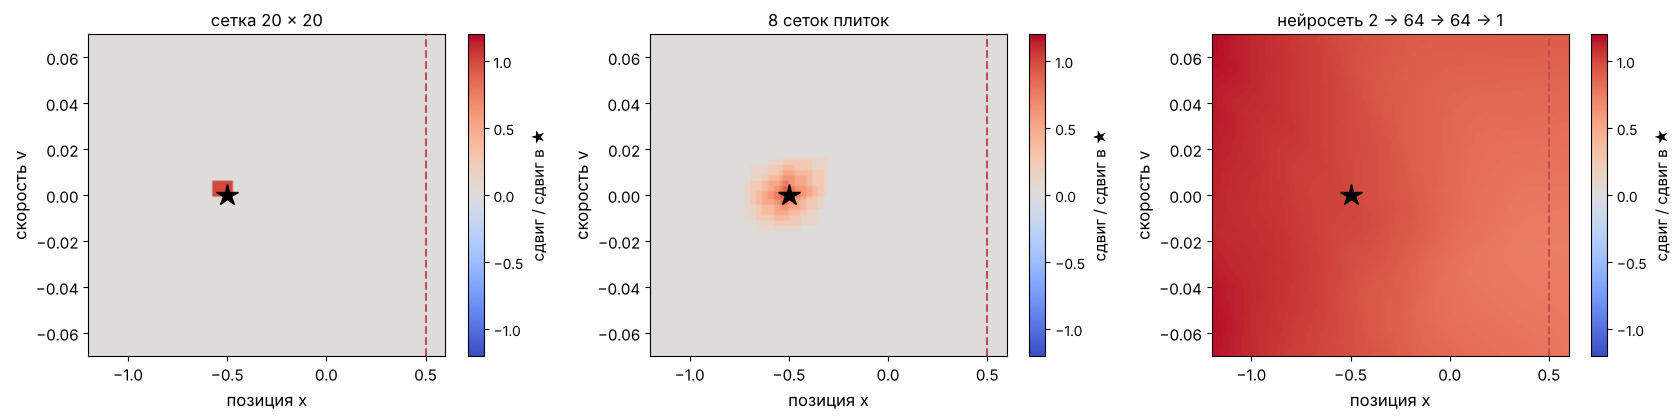

In [14]:
far = np.array([0.6, 0.07])                              # дальний угол поля: у флага на полной скорости
shift, shift_star = footprint_net(net, star, points, target=-10.0, lr=0.01)
far_index = np.argmin((np.abs(points - far) / (HIGH - LOW)).sum(axis=1))   # ближайшая к углу точка карты
print(f"сдвиг оценки в ★: {shift_star:+.3f},  в дальнем углу ({far[0]}, {far[1]}): {shift[far_index]:+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
plot_footprint(footprint_linear(grid, star, points), shape, star, ax=axes[0], title="сетка 20 × 20")
plot_footprint(footprint_linear(tiles, star, points), shape, star, ax=axes[1], title="8 сеток плиток")
plot_footprint(shift / shift_star, shape, star, ax=axes[2], title="нейросеть 2 → 64 → 64 → 1")
plt.tight_layout(); plt.show()

Ответ **C** — по всему полю. Оценка сдвинулась на −0.339 в самой ★ и на −0.309 в дальнем углу поля — у флага на полной скорости.

Почему так выходит. Шаг градиента сдвигает веса на $\Delta w = \alpha\, \delta\, \nabla \hat v(★)$, где $\delta = y - \hat v(★)$. Оценка в другой точке $s'$ меняется приблизительно на произведение её градиента на этот сдвиг:

$$\Delta \hat v(s') \approx \nabla \hat v(s') \cdot \Delta w = \alpha\, \delta\; \nabla \hat v(s') \cdot \nabla \hat v(★).$$

Это та же формула, что в разделе 2: у линейной функции $\nabla \hat q(s) = x(s)$, и скалярное произведение $\nabla \hat q(s') \cdot \nabla \hat q(★) = \sum_i x_i(s') x_i(★)$ — число общих плиток. У сети все точки считаются одними и теми же весами, и градиенты в разных точках почти никогда не перпендикулярны. Проверим формулу числом в дальнем углу.

In [15]:
def gradient(net, s):
    # градиент выхода сети по всем параметрам — один длинный вектор
    net.zero_grad()
    net(torch.tensor(normalize(s)[None], dtype=torch.float32)).squeeze().backward()
    return torch.cat([p.grad.flatten() for p in net.parameters()]).clone()

net = make_net()
delta = -10.0 - net(torch.tensor(normalize(star)[None], dtype=torch.float32)).item()
predicted = 0.01 * delta * torch.dot(gradient(net, far), gradient(net, star)).item()
print(f"по формуле α δ ∇v̂(s′)·∇v̂(★): {predicted:+.3f},   на деле: {shift[far_index]:+.3f}")

по формуле α δ ∇v̂(s′)·∇v̂(★): -0.308,   на деле: -0.309


Общие веса — и польза, и опасность. Польза — обобщение: похожие кадры игры получат похожие оценки, даже если агент видел только один из них. Опасность: обучение в одной точке сдвигает оценки там, где данных нет, — а SARSA и Q-learning строят цели из этих же оценок. В следующем разделе — к чему это может привести.

**Одной строкой:** у сети одно обновление сдвигает оценку на $\alpha\, \delta\, \nabla \hat v(s') \cdot \nabla \hat v(s)$ — почти по всему полю.

## 5. Смертельная триада

Задача раздела: найти самый маленький пример, где обучение по своей же оценке с общими весами разлетается, и понять, какие условия для этого нужны.

**Задача.** Два состояния, 1 и 2. Из состояния 1 агент переходит в 2 с наградой 0, из 2 эпизод кончается тоже с наградой 0. Все награды — нули, поэтому настоящие ценности $v(1) = v(2) = 0$.

**Оценка** — один общий вес $w$ и по одному признаку на состояние: $x(1) = 1$, $x(2) = 2$. Тогда $\hat v(1) = w$, $\hat v(2) = 2w$, и точный ответ $w = 0$ в такой функции есть.

**Данные** собрала другая стратегия, как лог случайной стратегии в лекции 4: в логе только переходы $1 \to 2$, перехода из 2 в конец нет. Обучение по чужим данным — off-policy.

**Обновление** — semi-gradient TD из раздела 3, но для $\hat v$ вместо $\hat q$:

$$\delta = 0 + \gamma\, \hat v(2) - \hat v(1) = (2\gamma - 1)\, w, \qquad w \leftarrow w + \alpha\, \delta\, x(1) = \big(1 + \alpha(2\gamma - 1)\big)\, w.$$

**Вопрос 5 (голосуем).** Начинаем с $w = 1$, $\gamma = 0.9$, $\alpha = 0.1$ и делаем 100 обновлений по переходу $1 \to 2$. Что будет с $w$?

* **A.** придёт к 0 — награды же нули;
* **B.** останется 1;
* **C.** вырастет до тысяч;
* **D.** будет колебаться около 0.

Проверим: сто раз применим обновление.

In [16]:
def two_states(gamma=0.9, alpha=0.1, w=1.0, updates=100):
    history = [w]
    for _ in range(updates):
        delta = 0 + gamma * (2 * w) - w          # цель r + γ v̂(2) минус v̂(1); v̂(1) = w, v̂(2) = 2w
        w = w + alpha * delta * 1                # признак состояния 1: x(1) = 1
        history.append(w)
    return np.array(history)

triad = two_states()
print(f"множитель за одно обновление: 1 + α(2γ − 1) = {1 + 0.1 * (2 * 0.9 - 1):.2f}")
print(f"w после 100 обновлений: {triad[-1]:.0f}")

множитель за одно обновление: 1 + α(2γ − 1) = 1.08
w после 100 обновлений: 2200


Ответ **C** — вырастет до тысяч: $w$ выросло до 2200, ведь $1.08^{100} \approx 2200$.

Почему так выходит. Обновление поднимает $\hat v(1)$ к цели $\gamma\, \hat v(2) = 1.8\,w$. Но поднять $\hat v(1)$ можно только через общий вес $w$, а он поднимает и $\hat v(2) = 2w$ — вдвое сильнее. Цель убегает быстрее оценки. Опустить $\hat v(2)$ мог бы переход из состояния 2 в конец, но его в данных нет. Из множителя виден и порог: $1 + \alpha(2\gamma - 1) > 1$ при любом $\gamma > 0.5$. Проверим порог:

In [17]:
for g in (0.4, 0.5, 0.6, 0.9):
    print(f"γ = {g}:  множитель {1 + 0.1 * (2 * g - 1):.2f},   w после 100 обновлений: {two_states(gamma=g)[-1]:.3g}")

γ = 0.4:  множитель 0.98,   w после 100 обновлений: 0.133
γ = 0.5:  множитель 1.00,   w после 100 обновлений: 1
γ = 0.6:  множитель 1.02,   w после 100 обновлений: 7.24
γ = 0.9:  множитель 1.08,   w после 100 обновлений: 2.2e+03


Разлетание держится на трёх условиях. Уберём по одному — каждый раз меняется ровно одно:

1. **on-policy вместо чужих данных** — данные собирает та стратегия, которую оцениваем: после $1 \to 2$ идёт переход из 2 в конец, и он тоже обновляет вес: $\delta = 0 - 2w$, $w \leftarrow w + \alpha\, \delta\, x(2) = (1 - 4\alpha)\, w$;
2. **Монте-Карло вместо своей оценки в цели** — цель равна сумме наград эпизода $G = 0$: $w \leftarrow w + \alpha\,(0 - w)$;
3. **таблица вместо общего веса** — у каждого состояния свой вес, $\hat v(1) = w_1$ и $\hat v(2) = w_2$, начинаем с тех же 1 и 2: $w_1 \leftarrow w_1 + \alpha\,(\gamma w_2 - w_1)$, а $w_2$ не обновляется — перехода из 2 нет в данных.

on-policy вместо чужих данных    v̂(1) после 100 шагов: 1.4e-19
Монте-Карло вместо своей оценки  v̂(1) после 100 шагов: 2.7e-05
таблица вместо общего веса       v̂(1) после 100 шагов: 1.8


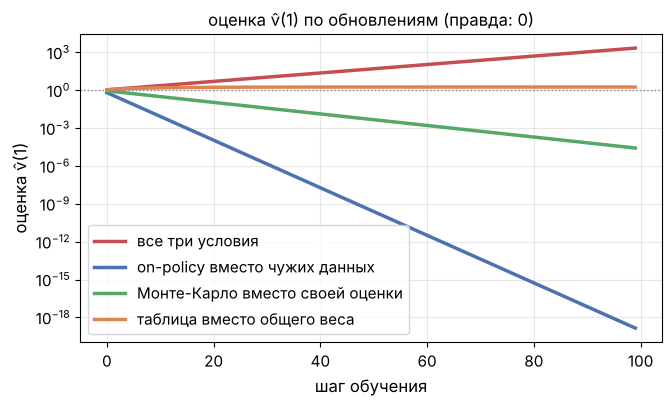

In [18]:
def variant(kind, gamma=0.9, alpha=0.1, updates=100):
    w, w1, w2 = 1.0, 1.0, 2.0
    history = []
    for _ in range(updates):
        if kind == "on-policy":                  # шаг обучения — эпизод: переход 1 → 2, затем 2 → конец
            w += alpha * (gamma * 2 * w - w) * 1
            w += alpha * (0 - 2 * w) * 2
        elif kind == "Монте-Карло":              # цель — сумма наград эпизода, G = 0
            w += alpha * (0 - w) * 1
        elif kind == "таблица":                  # свой вес у каждого состояния
            w1 += alpha * (gamma * w2 - w1)
        history.append(w1 if kind == "таблица" else w)
    return np.array(history)

names = {"on-policy": "on-policy вместо чужих данных", "Монте-Карло": "Монте-Карло вместо своей оценки",
         "таблица": "таблица вместо общего веса"}
curves = {"все три условия": triad[1:]}
for kind, name in names.items():
    curves[name] = variant(kind)
    print(f"{name:32s} v̂(1) после 100 шагов: {curves[name][-1]:.2g}")
plot_w_curves(curves, title="оценка v̂(1) по обновлениям (правда: 0)")
plt.show()

С чужими данными, своей оценкой в цели и общим весом $w$ разлетается; уберите любое из трёх — и не разлетается. С таблицей $\hat v(1)$ приходит к $\gamma\, w_2 = 1.8$ и там остаётся: ответ неверный, потому что $\hat v(2) = 2$ без данных не учится, но конечный.

Эти три условия вместе называют **смертельной триадой** (deadly triad, Саттон и Барто, раздел 11.3):

* **аппроксимация** — общие веса у многих состояний (линейная функция, сеть);
* **бутстрэппинг** — в цели стоит своя же оценка $\hat v(s')$, а не сумма наград;
* **off-policy** — данные собраны не той стратегией, которую оцениваем.

Это не особенность игрушки: Бэрд (1995) построил пример из семи состояний, где оценка разлетается даже при обновлении по точной модели среды, без случайных выборок.

**Мост к DQN.** В DQN есть все три: нейросеть, цель Q-learning $r + \gamma \max_{a'} Q(s', a')$ и обучение по буферу старых переходов. Гарантии, что обучение сойдётся, у DQN нет; приёмы, которые держат его обучение на практике, — тема лекции 7.

**Одной строкой:** аппроксимация, бутстрэппинг и off-policy вместе могут развалить обучение даже при нулевых наградах; уберите любое из трёх — и пример сходится.

## 6. ⏱ Что приближаем: стратегию, ценность или обе

| метод | что считает функция с весами | где в курсе |
|---|---|---|
| REINFORCE со стратегией-сетью | вероятности действий $\pi(a \mid s)$ | лекция 5, CartPole |
| Cross-Entropy с сетью (Deep CEM) | $\pi(a \mid s)$; в оценке градиента вес 1 у элитных эпизодов и 0 у остальных | лекция 5 |
| semi-gradient SARSA | $\hat q(s, a)$ — плитками или сетью | сегодня |
| DQN | $Q(s, a)$ — сетью | лекция 7 |
| actor-critic | и $\pi(a \mid s)$, и $\hat v(s)$ | лекция 9 |

Стратегия-сеть в лекции 5 обучилась без особых приёмов, и это не случайно: REINFORCE не подставляет в цель свою оценку (вес — настоящие награды $G_t$) и учится только на свежих эпизодах своей стратегии. Из трёх условий триады у него одно — аппроксимация.

**Одной строкой:** сетью можно приближать стратегию, ценность или обе; опасная триада возникает только там, где в цели стоит своя же оценка.

## 7. Итоги и где это работает

1. **Таблица учит каждую клетку отдельно.** На горной машине после 300 эпизодов 156 клеток из 400 не обновлялись ни разу и хранят нули.
2. **Таблица — линейная функция** $\hat q(s, a) = \sum_i x_i(s)\, W[i, a]$ с признаками-клетками, а её обновление — шаг градиентного спуска по $\tfrac12(y - \hat q)^2$.
3. **Semi-gradient:** в RL цель $r + \gamma\, \hat q(s', a')$ — своя же оценка; её считают числом и двигают только $\hat q(s, a)$. В PyTorch — `.detach()`.
4. **Одно обновление сдвигает оценку в $s'$ на $\alpha\, \delta\, \nabla \hat q(s') \cdot \nabla \hat q(s)$:** у таблицы — в своей клетке, у плиток — в пятне (обобщение: в последних 50 эпизодах машина доезжает в 88–96 % эпизодов против 0–6 % у сетки), у сети — почти по всему полю.
5. **Смертельная триада:** аппроксимация + бутстрэппинг + off-policy могут развалить обучение — в примере с весами $w$ и $2w$ оценка выросла до 2200 при нулевых наградах; уберите любое из трёх, и пример сходится.

**Где это работает в жизни.**

* **Нарды.** TD-Gammon (Тезауро, 1992–1995): нейросеть оценивает позицию и учится TD-ошибкой на партиях против себя — дошла до уровня сильнейших игроков, хотя гарантий сходимости у такого обучения нет.
* **Игры Atari.** DQN (Mnih и др., 2015): Q-функция — сверточная сеть по пикселям экрана; одна и та же программа учится 49 играм. Это следующая лекция.
* **Го.** В AlphaGo, кроме сети-стратегии из лекции 5, есть сеть ценности: она оценивает позицию на доске, как $\hat v(s)$ сегодня.

Словарь лекции: **аппроксимация функции, признаки, плитки (tile coding), линейная функция ценности, semi-gradient, обобщение, смертельная триада (аппроксимация, бутстрэппинг, off-policy)**.

## Литература

* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд.: глава 9 (аппроксимация, плитки — раздел 9.5), глава 10 (горная машина — пример 10.1), глава 11 (пример с $w$ и $2w$ — раздел 11.2, смертельная триада — раздел 11.3). [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)
* Tsitsiklis J., Van Roy B. *An analysis of temporal-difference learning with function approximation*. IEEE Transactions on Automatic Control, 1997 — когда линейный TD сходится.
* Baird L. *Residual algorithms: reinforcement learning with function approximation*. ICML, 1995 — пример из семи состояний.
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem).

## На семинаре и дома

* **Домашка блока 3** — дедлайн объявит преподаватель.